<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/day19_Voting_Stacking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick train.csv

Saving train.csv to train.csv


{'train.csv': b'school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other,G3\n0,1,19,0,1,1,3,3,1,2,1,0,0,0,1,1,1,0,1,4,5,3,1,2,5,0,15,12,0,1,0,0,0,0,1,0,0,0,1,0,0,12\n1,0,18,1,1,1,2,3,2,1,0,0,1,1,0,1,1,1,1,5,2,3,1,2,4,0,11,10,0,0,0,0,0,0,1,0,0,0,0,0,0,10\n0,0,19,0,1,1,2,3,1,3,1,0,0,0,0,1,1,1,1,4,1,2,1,1,3,20,13,11,0,1,0,0,0,1,0,0,0,0,1,0,1,11\n0,1,15,1,1,1,4,3,1,2,0,0,1,1,1,1,1,1,0,4,3,3,2,3,5,6,9,9,0,0,0,1,0,1,0,0,1,0,0,1,0,10\n0,1,17,1,0,0,4,1,2,1,0,0,0,1,1,1,1,1,1,4,5,4,2,4,5,20,8,8,0,0,1,0,0,1,0,0,1,0,0,1,0,8\n1,0,18,1,0,1,3,1,1,2,0,0,1,1,0,1,1,1,0,4,3,4,1,1,1,0,7,9,0,0,0,1,0,0,1,0,0,0,0,1,0,8\n0,0,16,1,1,1,4,4,1,3,0,0,1,1,1,1,1,1,0,3,2,3,1,2,2,6,13,14,0,0,1,0,0,0,1,0,0,0,

In [2]:
# Cell 1: setup (same data and folds as Days 16-18)
import itertools
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import (RepeatedKFold, RepeatedStratifiedKFold, KFold,
                                     cross_validate, cross_val_predict)
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor,
                              VotingRegressor, StackingRegressor,
                              RandomForestClassifier, GradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.linear_model import RidgeCV, LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor

sns.set_theme(style="whitegrid")
train = pd.read_csv("train.csv")
y = train["G3"]
y_risk = (y < 10).astype(int)
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

cv_reg = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)       # same folds as Days 16-18
cv_clf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
inner = KFold(n_splits=5, shuffle=True, random_state=1)

rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

def make_models():
    return {
        "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 40))),
        "Random Forest": RandomForestRegressor(n_estimators=300, max_features=0.33,
                                               min_samples_leaf=3, random_state=42, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, learning_rate=0.05,
                                                       max_depth=2, subsample=0.8, random_state=42),
    }
names = list(make_models())
print("Training students:", len(train), "| base models:", names)

Training students: 285 | base models: ['Ridge', 'Random Forest', 'Gradient Boosting']


In [3]:
# Cell 2: the arithmetic of averaging (assumes equal error variance for both models)
print("Two models averaged. The gain depends on how correlated their errors are:\n")
for rho in [0.0, 0.5, 0.8, 0.9, 0.95, 1.0]:
    factor = np.sqrt((1 + rho) / 2)
    print(f"  error correlation {rho:4.2f} -> averaged RMSE = {factor:.3f} x a single model's "
          f"({(1 - factor) * 100:4.1f}% lower)")

Two models averaged. The gain depends on how correlated their errors are:

  error correlation 0.00 -> averaged RMSE = 0.707 x a single model's (29.3% lower)
  error correlation 0.50 -> averaged RMSE = 0.866 x a single model's (13.4% lower)
  error correlation 0.80 -> averaged RMSE = 0.949 x a single model's ( 5.1% lower)
  error correlation 0.90 -> averaged RMSE = 0.975 x a single model's ( 2.5% lower)
  error correlation 0.95 -> averaged RMSE = 0.987 x a single model's ( 1.3% lower)
  error correlation 1.00 -> averaged RMSE = 1.000 x a single model's ( 0.0% lower)


early (no G1/G2)   average pairwise error correlation: 0.97
all features       average pairwise error correlation: 0.81


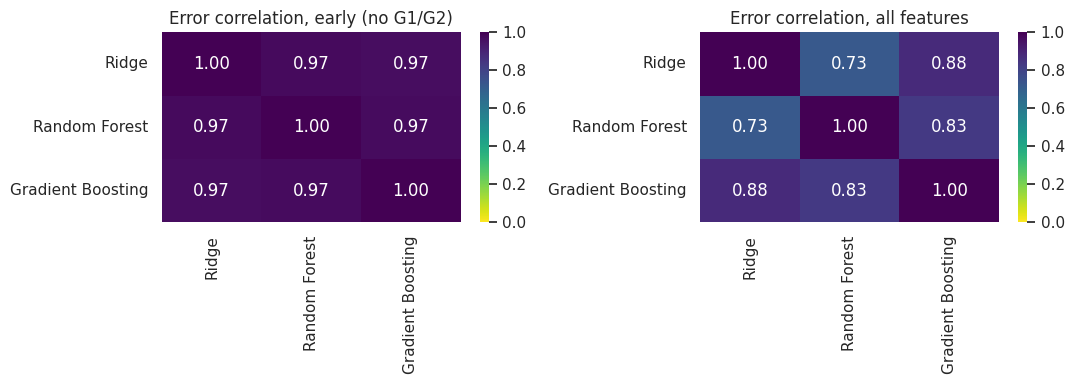

In [4]:
# Cell 3: out-of-fold predictions, and how correlated are the models' errors?
oof = {}
for fname, X in feature_sets.items():
    for mname, m in make_models().items():
        oof[(fname, mname)] = cross_val_predict(m, X.values, y.values, cv=kf)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, fname in zip(axes, feature_sets):
    resid = pd.DataFrame({m: y.values - oof[(fname, m)] for m in names})
    c = resid.corr()
    sns.heatmap(c, annot=True, fmt=".2f", cmap="viridis_r", vmin=0, vmax=1, ax=ax)
    ax.set_title(f"Error correlation, {fname}")
    pairs = [c.loc[a, b] for a, b in itertools.combinations(names, 2)]
    print(f"{fname:18s} average pairwise error correlation: {np.mean(pairs):.2f}")
plt.tight_layout()
plt.savefig("error_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# Cell 4: simple averages of every combination (one 5-fold run, pooled out-of-fold predictions)
rows = []
for fname in feature_sets:
    for r in [1, 2, 3]:
        for combo in itertools.combinations(names, r):
            p = np.mean([oof[(fname, m)] for m in combo], axis=0)
            rows.append({"features": fname, "members": " + ".join(combo),
                         "n": r, "RMSE": round(rmse(y, p), 3)})
blend = pd.DataFrame(rows)
for fname in feature_sets:
    print(f"\n{fname}")
    print(blend[blend.features == fname].sort_values("RMSE")[["members", "RMSE"]].to_string(index=False))


early (no G1/G2)
                                  members  RMSE
                Ridge + Gradient Boosting 2.939
Ridge + Random Forest + Gradient Boosting 2.944
                    Ridge + Random Forest 2.957
        Random Forest + Gradient Boosting 2.958
                                    Ridge 2.962
                        Gradient Boosting 2.968
                            Random Forest 2.990

all features
                                  members  RMSE
                Ridge + Gradient Boosting 0.866
                        Gradient Boosting 0.879
Ridge + Random Forest + Gradient Boosting 0.884
                                    Ridge 0.906
                    Ridge + Random Forest 0.910
        Random Forest + Gradient Boosting 0.925
                            Random Forest 1.052


In [6]:
# Cell 5: stacking from scratch, the honest way and the leaky way
def stack_fold(Xtr, ytr, Xva, leaky):
    P_tr, P_va = [], []
    for name, m in make_models().items():
        fitted = clone(m).fit(Xtr, ytr)
        P_va.append(fitted.predict(Xva))
        if leaky:                                        # WRONG: predictions on the students it trained on
            P_tr.append(fitted.predict(Xtr))
        else:                                            # RIGHT: out-of-fold predictions
            P_tr.append(cross_val_predict(clone(m), Xtr, ytr, cv=inner))
    P_tr, P_va = np.column_stack(P_tr), np.column_stack(P_va)
    meta = LinearRegression(positive=True).fit(P_tr, ytr)
    return meta.predict(P_va), P_va, meta.coef_

summary, weight_tables = [], {}
for fname, X in feature_sets.items():
    Xv, yv = X.values, y.values
    res = {k: [] for k in ["honest stack", "leaky stack", "equal average"] + names}
    w = {"honest stack": [], "leaky stack": []}
    for tr, va in kf.split(Xv):
        for mode in ["honest stack", "leaky stack"]:
            p, P_va, coef = stack_fold(Xv[tr], yv[tr], Xv[va], leaky=(mode == "leaky stack"))
            res[mode].append(rmse(yv[va], p))
            w[mode].append(coef)
            if mode == "honest stack":
                res["equal average"].append(rmse(yv[va], P_va.mean(axis=1)))
                for j, nm in enumerate(names):
                    res[nm].append(rmse(yv[va], P_va[:, j]))
    summary.append(pd.Series({k: np.mean(v) for k, v in res.items()}, name=fname).round(3))
    weight_tables[fname] = pd.DataFrame({k: np.mean(v, axis=0) for k, v in w.items()}, index=names).round(2)

print("Mean validation RMSE across 5 folds (lower is better):")
display(pd.DataFrame(summary).T)
for fname, wt in weight_tables.items():
    print(f"\nAverage meta-learner weights, {fname}:")
    display(wt)

Mean validation RMSE across 5 folds (lower is better):


,early (no G1/G2),all features
honest stack,2.974,0.868
leaky stack,3.059,0.924
equal average,2.941,0.883
Ridge,2.961,0.903
Random Forest,2.985,1.052
Gradient Boosting,2.964,0.876



Average meta-learner weights, early (no G1/G2):


,honest stack,leaky stack
Ridge,0.53,0.00
Random Forest,0.40,1.79
Gradient Boosting,0.17,0.00



Average meta-learner weights, all features:


,honest stack,leaky stack
Ridge,0.31,0.00
Random Forest,0.09,0.73
Gradient Boosting,0.62,0.35


In [7]:
# Cell 6: scikit-learn's VotingRegressor and StackingRegressor on the repeated folds (a few minutes)
def ens_models():
    est = list(make_models().items())
    return {
        "Voting (equal weights)": VotingRegressor(est),
        "Stacking (positive linear)": StackingRegressor(est, final_estimator=LinearRegression(positive=True), cv=5),
    }

def fold_rmse(model, X):
    r = cross_validate(model, X, y, cv=cv_reg, scoring="neg_root_mean_squared_error")
    return -r["test_score"]

all_models = {"Baseline (mean)": DummyRegressor(), **make_models(), **ens_models()}
scores = {}
for fname, X in feature_sets.items():
    for mname, m in all_models.items():
        scores[(fname, mname)] = fold_rmse(m, X)

rows = []
for fname in feature_sets:
    base = scores[(fname, "Baseline (mean)")]
    best_member = min(names, key=lambda m: scores[(fname, m)].mean())
    for mname in names + ["Voting (equal weights)", "Stacking (positive linear)"]:
        s = scores[(fname, mname)]
        is_ens = mname not in names
        rows.append({"features": fname, "model": mname,
                     "RMSE": round(s.mean(), 3), "std": round(s.std(), 3),
                     "gain over baseline %": round(100 * (base - s).mean() / base.mean(), 1),
                     "folds better than baseline": f"{(base - s > 0).sum()}/{len(s)}",
                     f"folds better than best member": (
                         f"{(scores[(fname, best_member)] - s > 0).sum()}/{len(s)} (vs {best_member})"
                         if is_ens else "")})
ens_table = pd.DataFrame(rows)
ens_table

,features,model,RMSE,std,gain over baseline %,folds better than baseline,folds better than best member
0,early (no G1/G2),Ridge,2.966,0.130,9.2,15/15,
1,early (no G1/G2),Random Forest,2.980,0.149,8.8,15/15,
2,early (no G1/G2),Gradient Boosting,2.967,0.141,9.2,14/15,
3,early (no G1/G2),Voting (equal weights),2.940,0.131,10.0,15/15,10/15 (vs Ridge)
4,early (no G1/G2),Stacking (positive linear),2.973,0.152,9.0,15/15,9/15 (vs Ridge)
5,all features,Ridge,0.903,0.082,72.4,15/15,
6,all features,Random Forest,1.038,0.074,68.2,15/15,
7,all features,Gradient Boosting,0.861,0.073,73.6,15/15,
8,all features,Voting (equal weights),0.872,0.072,73.3,15/15,6/15 (vs Gradient Boosting)
9,all features,Stacking (positive linear),0.854,0.081,73.8,15/15,10/15 (vs Gradient Boosting)


In [8]:
# Cell 7: what weights does the stacked model give each base model? (fitted on all training students)
for fname, X in feature_sets.items():
    st = ens_models()["Stacking (positive linear)"].fit(X, y)
    coefs = pd.Series(st.final_estimator_.coef_, index=names).round(3)
    print(f"{fname:18s} weights: {coefs.to_dict()} | intercept {st.final_estimator_.intercept_:.2f}"
          f" | sum of weights {coefs.sum():.2f}")

early (no G1/G2)   weights: {'Ridge': 0.389, 'Random Forest': 0.175, 'Gradient Boosting': 0.439} | intercept -0.01 | sum of weights 1.00
all features       weights: {'Ridge': 0.375, 'Random Forest': 0.0, 'Gradient Boosting': 0.631} | intercept -0.06 | sum of weights 1.01


In [9]:
# Cell 8: does diversity matter? Three tree ensembles vs three different model types
def trees_only():
    return VotingRegressor([
        ("RF", RandomForestRegressor(n_estimators=300, max_features=0.33, min_samples_leaf=3,
                                     random_state=42, n_jobs=-1)),
        ("ET", ExtraTreesRegressor(n_estimators=300, max_features=0.33, min_samples_leaf=3,
                                   random_state=42, n_jobs=-1)),
        ("GB", GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=2,
                                         subsample=0.8, random_state=42)),
    ])

rows = []
for fname, X in feature_sets.items():
    s_trees = fold_rmse(trees_only(), X)
    s_mixed = scores[(fname, "Voting (equal weights)")]
    rows.append({"features": fname,
                 "RF + ExtraTrees + GB (all trees)": round(s_trees.mean(), 3),
                 "Ridge + RF + GB (mixed types)": round(s_mixed.mean(), 3),
                 "folds mixed is better": f"{(s_trees - s_mixed > 0).sum()}/{len(s_trees)}"})
pd.DataFrame(rows)

,features,RF + ExtraTrees + GB (all trees),Ridge + RF + GB (mixed types),folds mixed is better
0,early (no G1/G2),2.939,2.940,6/15
1,all features,0.954,0.872,15/15


In [10]:
# Cell 9: the same idea for the at-risk classifier (soft voting and stacking)
def clf_members():
    return [("Logistic", make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))),
            ("Random Forest", RandomForestClassifier(n_estimators=300, max_features="sqrt",
                                                     min_samples_leaf=3, random_state=42, n_jobs=-1)),
            ("Gradient Boosting", GradientBoostingClassifier(n_estimators=100, learning_rate=0.05,
                                                             max_depth=2, subsample=0.8, random_state=42))]

clf_models = dict(clf_members())
clf_models["Soft voting"] = VotingClassifier(clf_members(), voting="soft")
clf_models["Stacking (logistic)"] = StackingClassifier(clf_members(), final_estimator=LogisticRegression(),
                                                        cv=5, stack_method="predict_proba")
rows = []
for fname, X in feature_sets.items():
    for mname, m in clf_models.items():
        r = cross_validate(m, X, y_risk, cv=cv_clf, scoring={"auc": "roc_auc", "ap": "average_precision"})
        rows.append({"features": fname, "model": mname,
                     "ROC AUC": round(r["test_auc"].mean(), 3), "AUC std": round(r["test_auc"].std(), 3),
                     "PR AUC": round(r["test_ap"].mean(), 3)})
clf_table = pd.DataFrame(rows)
print(f"At-risk share (the PR AUC of guessing): {y_risk.mean():.1%}")
clf_table

At-risk share (the PR AUC of guessing): 25.6%


,features,model,ROC AUC,AUC std,PR AUC
0,early (no G1/G2),Logistic,0.652,0.085,0.442
1,early (no G1/G2),Random Forest,0.663,0.059,0.428
2,early (no G1/G2),Gradient Boosting,0.657,0.061,0.406
3,early (no G1/G2),Soft voting,0.675,0.069,0.437
4,early (no G1/G2),Stacking (logistic),0.662,0.070,0.438
5,all features,Logistic,0.951,0.030,0.876
6,all features,Random Forest,0.952,0.030,0.882
7,all features,Gradient Boosting,0.962,0.023,0.888
8,all features,Soft voting,0.963,0.022,0.901
9,all features,Stacking (logistic),0.962,0.022,0.896


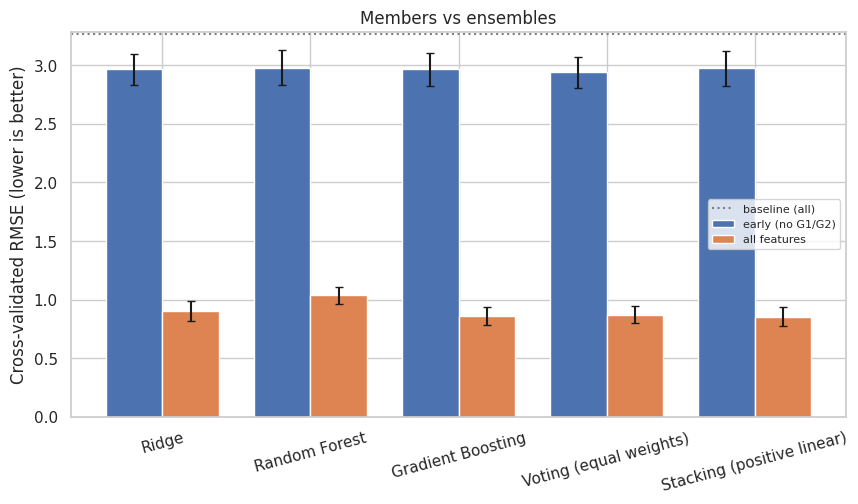

Saved phase4_day19_regression.csv, phase4_day19_classification.csv and phase4_day19_blends.csv


In [11]:
# Cell 10: summary figure and saved results
order = names + ["Voting (equal weights)", "Stacking (positive linear)"]
width = 0.38
plt.figure(figsize=(10, 5))
for i, fname in enumerate(feature_sets):
    sub = ens_table[ens_table.features == fname].set_index("model").loc[order]
    plt.bar(np.arange(len(order)) + i * width, sub["RMSE"], width, yerr=sub["std"], capsize=3, label=fname)
plt.axhline(scores[("all features", "Baseline (mean)")].mean(), color="gray", linestyle=":", label="baseline (all)")
plt.xticks(np.arange(len(order)) + width / 2, order, rotation=15)
plt.ylabel("Cross-validated RMSE (lower is better)")
plt.title("Members vs ensembles")
plt.legend(fontsize=8)
plt.savefig("ensemble_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

ens_table.to_csv("phase4_day19_regression.csv", index=False)
clf_table.to_csv("phase4_day19_classification.csv", index=False)
blend.to_csv("phase4_day19_blends.csv", index=False)
print("Saved phase4_day19_regression.csv, phase4_day19_classification.csv and phase4_day19_blends.csv")